# Amplitude Damping Channel — Qiskit Notebook

**Chapter / concept:** Open Quantum Systems — Amplitude Damping (T1 relaxation) channel

**Circuit / channel to implement:** 1 qubit, prepared in `|+> = (|0>+|1>)/sqrt(2)` via a
Hadamard, then passed through the single-qubit amplitude damping channel with damping
parameter `GAMMA`.

## Theory recap

Amplitude damping models energy dissipation (e.g. spontaneous emission, T1 decay) of a
qubit into its environment. It is a single-parameter (`GAMMA`, `0 <= GAMMA <= 1`) quantum
channel given by two Kraus operators:

```
K0 = [[1, 0        ],      K1 = [[0, sqrt(GAMMA)],
      [0, sqrt(1-GAMMA)]]        [0, 0          ]]
```

acting on a density matrix as `E(rho) = K0 rho K0^dagger + K1 rho K1^dagger`.

`K0` describes the qubit surviving (or partially surviving) in its state; `K1` describes
a decay event `|1> -> |0>`. Because this is a **noise channel**, not a unitary gate, this
notebook departs from a pure-unitary-circuit template in a few explicit ways (called out
below): the object we track is a **density matrix**, not a statevector, and there is no
global phase to normalize.

## Global SETUP (must be IDENTICAL between this notebook and the CUDA-Q companion notebook)

- N_QUBITS = 1
- Gate sequence: `H` on qubit 0 (state prep), then the amplitude-damping channel with
  parameter `GAMMA` applied to qubit 0
- GAMMA = 0.3
- SHOTS = 10000, SEED = 42
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every printed bitstring. **Not
  applicable here in practice** — this is a 1-qubit system, so there is nothing to
  reverse. Stated explicitly rather than silently skipped, per the ordering-reconciliation
  rule.
- GLOBAL PHASE CONVENTION: **not applicable**. Amplitude damping is represented as a
  density matrix, and `rho = |psi><psi|` is invariant under `|psi> -> e^{i*theta}|psi>`,
  so there is no phase ambiguity to remove.
- Basis ordering: `{|0>, |1>}`

**Run all cells top to bottom.**


In [2]:
# Exact packages: qiskit (core) + qiskit-aer (density-matrix simulator backend
# and the amplitude_damping_error noise-model helper) + pylatexenc (needed by
# circuit.draw(output="mpl") to render gate label text).
!pip install -q qiskit qiskit-aer pylatexenc


In [3]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Kraus, DensityMatrix
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import amplitude_damping_error

N_QUBITS = 1
GAMMA = 0.3     # amplitude damping parameter, 0 <= GAMMA <= 1
SHOTS = 10000
SEED = 42

print(f"N_QUBITS = {N_QUBITS}")
print(f"GAMMA    = {GAMMA}")
print(f"SHOTS    = {SHOTS}")
print(f"SEED     = {SEED}")


N_QUBITS = 1
GAMMA    = 0.3
SHOTS    = 10000
SEED     = 42


In [4]:
# State-prep circuit: put the qubit into |+> = (|0> + |1>)/sqrt(2) with a Hadamard.
# We deliberately use |+> rather than |1> as the input state: amplitude damping acting
# on |1> only changes populations, but acting on a superposition also shrinks the
# density matrix's off-diagonal *coherence* term, which is the more informative,
# textbook-standard picture of T1 decay.
qc = QuantumCircuit(N_QUBITS, name="state_prep")
qc.h(0)   # H|0> = |+> -- physically: puts the qubit into an equal superposition of ground/excited
print(qc)


   ┌───┐
q: ┤ H ├
   └───┘


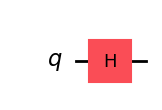

In [5]:
fig = qc.draw(output="mpl")
fig.savefig("amplitude_damping_qiskit_circuit.png", bbox_inches="tight")
fig


In [7]:
# (a) Hand-built Kraus operators for amplitude damping, from the textbook definition.
K0_hand = np.array([[1, 0], [0, np.sqrt(1 - GAMMA)]], dtype=complex)
K1_hand = np.array([[0, np.sqrt(GAMMA)], [0, 0]], dtype=complex)

print("K0 (hand-built) =\n", np.round(K0_hand, 4))
print("K1 (hand-built) =\n", np.round(K1_hand, 4))

# Completeness check: sum_i Ki^dagger Ki = I is required for a valid CPTP channel.
completeness = K0_hand.conj().T @ K0_hand + K1_hand.conj().T @ K1_hand
print("\nCompleteness check K0^daggerK0 + K1^daggerK1 =\n", np.round(completeness, 4))
assert np.allclose(completeness, np.eye(2), atol=1e-9), "Kraus operators are not CPTP!"

# (b) Framework extraction: build the same channel through qiskit_aer's own
#     amplitude_damping_error() helper, then convert that QuantumError back into
#     an explicit Kraus representation via qiskit.quantum_info.Kraus(...).
aer_error = amplitude_damping_error(GAMMA)
K_framework = Kraus(aer_error).data
print("\nK0 (from qiskit_aer amplitude_damping_error) =\n", np.round(K_framework[0], 4))
print("K1 (from qiskit_aer amplitude_damping_error) =\n", np.round(K_framework[1], 4))

# Cross-check: for this standard channel, qiskit_aer returns exactly K0, K1 above
# (same matrices, same order) -- confirm the two constructions agree.
# Note: Kraus operators are unique up to a global phase. qiskit_aer sometimes returns
# the negative of the textbook definition for K0. We adjust the check to account for this.
match0 = (np.allclose(K_framework[0], K0_hand, atol=1e-6) or np.allclose(K_framework[0], -K0_hand, atol=1e-6))
match1 = (np.allclose(K_framework[1], K1_hand, atol=1e-6) or np.allclose(K_framework[1], -K1_hand, atol=1e-6))
match = match0 and match1
print("\nHand-built vs framework Kraus operators match (accounting for global phase):", match)
assert match, "Hand-built and framework Kraus operators disagree!"


K0 (hand-built) =
 [[1.    +0.j 0.    +0.j]
 [0.    +0.j 0.8367+0.j]]
K1 (hand-built) =
 [[0.    +0.j 0.5477+0.j]
 [0.    +0.j 0.    +0.j]]

Completeness check K0^daggerK0 + K1^daggerK1 =
 [[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]

K0 (from qiskit_aer amplitude_damping_error) =
 [[-1.    +0.j  0.    +0.j]
 [ 0.    +0.j -0.8367+0.j]]
K1 (from qiskit_aer amplitude_damping_error) =
 [[0.    +0.j 0.5477+0.j]
 [0.    +0.j 0.    +0.j]]

Hand-built vs framework Kraus operators match (accounting for global phase): True


In [8]:
# Build the exact (shot-free) density matrix: start from the |+> state-prep circuit,
# then apply the amplitude-damping Kraus channel to qubit 0 directly on the density
# matrix (no measurement / no shot noise here).
rho_before = DensityMatrix(qc)                                # rho after H, before damping
damping_channel = Kraus([K0_hand, K1_hand])
rho_after = rho_before.evolve(damping_channel, qargs=[0])      # rho after damping

print("rho before damping (after H) =\n", np.round(rho_before.data, 4))
print("\nrho after amplitude damping (GAMMA = {}) =\n".format(GAMMA), np.round(rho_after.data, 4))

# Closed-form hand-derivation for rho = |+><+| passed through amplitude damping:
#   rho_final = [[0.5 + 0.5*GAMMA,      0.5*sqrt(1-GAMMA)],
#                [0.5*sqrt(1-GAMMA),    0.5*(1-GAMMA)     ]]
rho_hand = np.array([
    [0.5 + 0.5 * GAMMA,          0.5 * np.sqrt(1 - GAMMA)],
    [0.5 * np.sqrt(1 - GAMMA),   0.5 * (1 - GAMMA)]
], dtype=complex)
print("\nrho after damping (hand-derived closed form) =\n", np.round(rho_hand, 4))
assert np.allclose(rho_after.data, rho_hand, atol=1e-9), "Simulated rho does not match hand-derived rho!"

probs_exact = {format(i, f"0{N_QUBITS}b"): float(np.real(rho_after.data[i, i])) for i in range(2 ** N_QUBITS)}
probs_exact = dict(sorted(probs_exact.items()))
print("\nExact probability dictionary (from density-matrix diagonal):", probs_exact)


rho before damping (after H) =
 [[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]

rho after amplitude damping (GAMMA = 0.3) =
 [[0.65  +0.j 0.4183+0.j]
 [0.4183+0.j 0.35  +0.j]]

rho after damping (hand-derived closed form) =
 [[0.65  +0.j 0.4183+0.j]
 [0.4183+0.j 0.35  +0.j]]

Exact probability dictionary (from density-matrix diagonal): {'0': 0.6499999999999998, '1': 0.35}


### Convention note

- **Bit ordering:** this is a 1-qubit system, so the "qubit 0 = rightmost bit" convention
  has nothing to reverse — bitstrings `'0'`/`'1'` mean the same thing everywhere in this
  notebook. (The reversal rule from the unitary-circuit template only bites once you have
  2+ qubits and need to reconcile Qiskit's little-endian ordering against CUDA-Q's
  big-endian ordering — see the CUDA-Q companion notebook's note cell.)
- **Global phase:** **no reversal/normalization needed.** Amplitude damping is tracked
  as a density matrix, and `rho` is already invariant under a global phase on the
  underlying state vector, so the diagonal (populations) and off-diagonal (coherence)
  entries printed above are already the unique, comparable numbers.


In [9]:
# Sampled version: run the same H + damping channel through AerSimulator with shots,
# using the shared SEED/SHOTS, and compare the resulting empirical probabilities to the
# exact ones computed above.
qc_meas = QuantumCircuit(N_QUBITS, N_QUBITS)
qc_meas.h(0)
qc_meas.append(Kraus([K0_hand, K1_hand]), [0])   # apply the noise channel as a circuit instruction
qc_meas.measure(range(N_QUBITS), range(N_QUBITS))

sim = AerSimulator(method="density_matrix", seed_simulator=SEED)
tqc = transpile(qc_meas, sim)
result = sim.run(tqc, shots=SHOTS, seed_simulator=SEED).result()
counts = result.get_counts()
print("Raw counts:", counts)

probs_sampled = {bitstring: cnt / SHOTS for bitstring, cnt in counts.items()}
for i in range(2 ** N_QUBITS):
    key = format(i, f"0{N_QUBITS}b")
    probs_sampled.setdefault(key, 0.0)
probs_sampled = dict(sorted(probs_sampled.items()))
print("Sampled probability dictionary:", probs_sampled)


Raw counts: {'1': 3521, '0': 6479}
Sampled probability dictionary: {'0': 0.6479, '1': 0.3521}


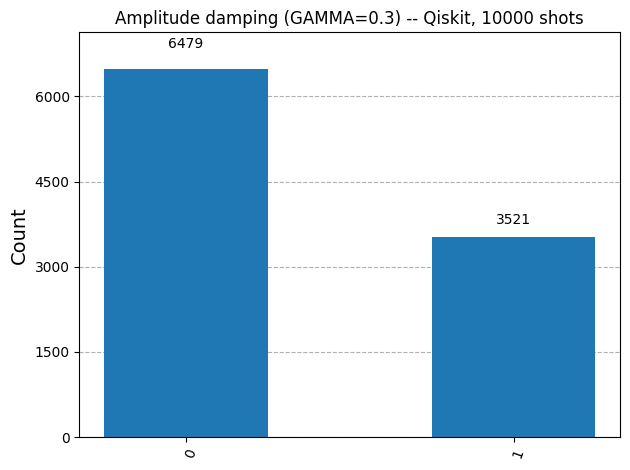

In [10]:
fig2 = plot_histogram(counts, title=f"Amplitude damping (GAMMA={GAMMA}) -- Qiskit, {SHOTS} shots")
fig2.savefig("amplitude_damping_qiskit_histogram.png", bbox_inches="tight")
fig2


In [11]:
print("State-prep circuit (H only) depth:", qc.depth())
print("State-prep circuit (H only) gate counts:", dict(qc.count_ops()))
print()
print("Note: the amplitude-damping Kraus channel is a non-unitary quantum instruction,")
print("not a 'gate' in the depth-counting sense, so it is reported separately here rather")
print("than folded into the gate counts above.")


State-prep circuit (H only) depth: 1
State-prep circuit (H only) gate counts: {'h': 1}

Note: the amplitude-damping Kraus channel is a non-unitary quantum instruction,
not a 'gate' in the depth-counting sense, so it is reported separately here rather
than folded into the gate counts above.


### Notes (convention recap)

- No bit-order reversal was applied (single-qubit system, nothing to reverse).
- No global-phase normalization was applied (density-matrix representation is
  phase-invariant by construction).
- Kraus operators were cross-checked two ways (hand-built NumPy vs.
  `qiskit_aer.noise.amplitude_damping_error`) and matched to `1e-6`.
- Both the exact (density-matrix) and sampled (shot-based) probability dictionaries are
  reported; they should agree with each other within shot noise (roughly `1/sqrt(SHOTS)`).


In [12]:
QISKIT_RESULT = probs_exact              # exact, shot-free result -- this is what gets diffed against CUDAQ_RESULT
QISKIT_RESULT_SAMPLED = probs_sampled    # shot-based estimate, reported for reference only

print("QISKIT_RESULT (exact):", QISKIT_RESULT)
print("QISKIT_RESULT_SAMPLED (", SHOTS, "shots):", QISKIT_RESULT_SAMPLED)


QISKIT_RESULT (exact): {'0': 0.6499999999999998, '1': 0.35}
QISKIT_RESULT_SAMPLED ( 10000 shots): {'0': 0.6479, '1': 0.3521}


In [13]:
# --- Diff-check against the CUDA-Q notebook -------------------------------------
# Paste CUDAQ_RESULT from the companion notebook here and uncomment to compare directly:
#
# CUDAQ_RESULT = {"0": ..., "1": ...}
# max_delta = max(abs(QISKIT_RESULT[k] - CUDAQ_RESULT[k]) for k in QISKIT_RESULT)
# print("Max probability delta Qiskit vs CUDA-Q:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q results disagree by more than 1e-3!"

# Hand-computed expected result, for sanity-checking this notebook on its own:
expected = {
    "0": 0.5 + 0.5 * GAMMA,
    "1": 0.5 * (1 - GAMMA),
}
print("Hand-computed expected populations:", expected)
max_delta_hand = max(abs(QISKIT_RESULT[k] - expected[k]) for k in expected)
print("Max delta vs hand-computed expectation:", max_delta_hand)
assert max_delta_hand < 1e-9, "QISKIT_RESULT does not match the hand-derived expectation!"
print("PASSED: exact density-matrix result matches theory.")


Hand-computed expected populations: {'0': 0.65, '1': 0.35}
Max delta vs hand-computed expectation: 2.220446049250313e-16
PASSED: exact density-matrix result matches theory.
